# 14 · Moving boundaries and transformed domains

Some problems do not live on a fixed grid: a melting front moves, an option's price is natural in the
logarithm of the asset, a boundary layer needs points where the solution turns. The method of lines absorbs
these through changes of variable - the moving boundary becomes an extra ODE on a fixed computational domain
(Landau's transformation), a transformed coordinate turns a variable-coefficient equation into a constant
one, and a stretched grid puts resolution where it is needed. This notebook works through Stefan melting,
Black-Scholes, and a boundary layer on uniform versus stretched grids.

**What you will learn**
- transform a moving-boundary problem to a fixed domain with an extra ODE
- recognise variable-coefficient parabolic problems as heat equations in transformed variables
- use stretched grids for boundary layers
- know the cell Peclet condition

**Before you start:** notebooks 01 and 05  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere engmolines is missing): install it from GitHub
    import engmolines
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engmolines"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engmolines import problems as pr, integrators as ti, grids, boundary as bc, operators as op, stencils as st
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Stefan melting: the Landau transformation

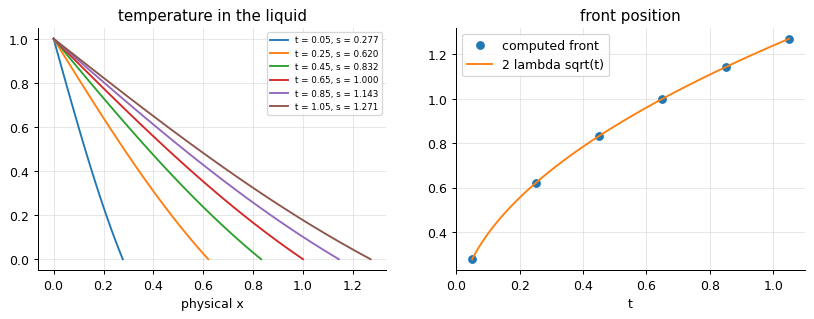

front error after t = 1: 1.8e-06; lambda from sqrt(pi) lambda e^(lambda^2) erf(lambda) = 1/St: 0.62006


In [2]:
p = pr.stefan(St=1.0)
s = p.solve("dopri", rtol=1e-8, atol=1e-10, n_out=5)
lam, t0 = p.params["lambda"], p.params["t0"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for t, y in zip(s.t, s.y):
    s_front = y[-1]
    axes[0].plot(p.x * s_front, y[:-1], label=f"t = {t + t0:.2f}, s = {s_front:.3f}")
axes[0].legend(fontsize=7); axes[0].set_xlabel("physical x"); axes[0].set_title("temperature in the liquid")
tt = np.linspace(t0, 1 + t0, 100)
axes[1].plot(s.t + t0, s.y[:, -1], "o", label="computed front"); axes[1].plot(tt, 2 * lam * np.sqrt(tt), label="2 lambda sqrt(t)"); axes[1].legend(); axes[1].set_xlabel("t"); axes[1].set_title("front position")
plt.show()
print(f"front error after t = 1: {abs(s.y[-1, -1] - 2 * lam * np.sqrt(1 + t0)):.1e}; lambda from sqrt(pi) lambda e^(lambda^2) erf(lambda) = 1/St: {lam:.5f}")

The liquid occupies 0 < x < s(t) with the front moving at the rate the heat flux into it dictates (the Stefan
condition). Mapping x to ξ = x/s(t) ∈ [0, 1] fixes the domain and adds the convective term ξ(ṡ/s) T_ξ and one
ODE for s - a standard method-of-lines system whose solution matches Neumann's similarity solution 2λ√t to
10⁻⁶. The front position is a state variable like any other, and the adaptive integrator treats it as such.

## Black-Scholes: a heat equation in disguise

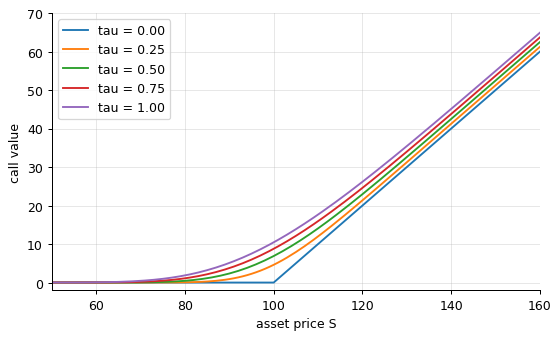

max error vs the Black-Scholes formula 2.50e-03; at the money C(100) = 10.4481 (exact 10.4506)
the far boundary follows S - K e^(-r tau): a time-dependent Dirichlet value, its rate dg/dtau supplied to the boundary node


In [3]:
p = pr.black_scholes(n=400, K=100.0, r=0.05, sigma=0.2, T=1.0)
s = p.solve("bdf", 1e-3, order=2, n_out=4)
for tau, y in zip(s.t, s.y):
    plt.plot(p.x, y, label=f"tau = {tau:.2f}")
plt.xlim(50, 160); plt.ylim(-2, 70); plt.xlabel("asset price S"); plt.ylabel("call value"); plt.legend(); plt.show()
print(f"max error vs the Black-Scholes formula {p.error(s):.2e}; at the money C(100) = {np.interp(100.0, p.x, s.y[-1]):.4f} (exact {p.exact(np.array([100.0]), 1.0)[0]:.4f})")
print("the far boundary follows S - K e^(-r tau): a time-dependent Dirichlet value, its rate dg/dtau supplied to the boundary node")

Written in time-to-expiry, the Black-Scholes equation is a parabolic equation with variable coefficients
½σ²S² and rS - a heat equation in the variable log S. The payoff's kink at S = K is smoothed instantly, as
rough data in a diffusion problem always are, and the method of lines prices the option to a few 10⁻³ of its
value with the plain finite-difference operator. (A log-price grid or a stretched grid around the strike would
do better per point; the exercise asks for it.)

## A boundary layer: uniform versus stretched grids

uniform, 60 points                  : smallest spacing 0.0167 (layer width 1/Pe = 0.005); steady error 2.86e-01; min value -0.250
stretched towards x = 1, 60 points  : smallest spacing 0.0007 (layer width 1/Pe = 0.005); steady error 1.85e-02; min value +0.000


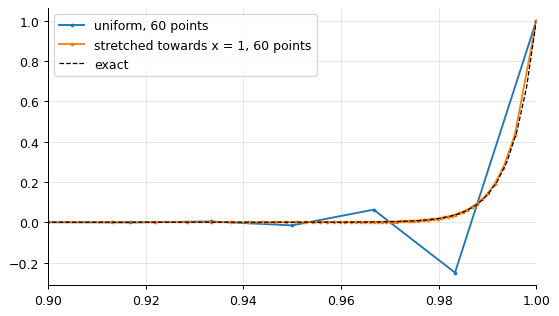

In [4]:
Pe = 200.0                                               # advection-diffusion u_t = -u_x + (1/Pe) u_xx, u(0) = 0, u(1) = 1: steady boundary layer of width 1/Pe at x = 1
exact = lambda x: (np.exp(Pe * (x - 1)) - np.exp(-Pe)) / (1 - np.exp(-Pe))   # noqa: E731
for name, g in (("uniform, 60 points", grids.uniform(0, 1, 60)), ("stretched towards x = 1, 60 points", grids.stretched(0, 1, 60, cluster=0.97, strength=2.5))):
    D1, D2 = st.diff_operator(g.x, 1, 2), st.diff_operator(g.x, 2, 2)
    def f(t, u, D1=D1, D2=D2):
        out = -D1(u) + D2(u) / Pe
        out[0] = out[-1] = 0.0
        return out
    u0 = np.zeros(g.n); u0[-1] = 1.0
    s = ti.bdf(f, u0, (0, 3.0), 0.01, 2, band=(3, 3), n_out=1)
    print(f"{name:<36}: smallest spacing {np.diff(g.x).min():.4f} (layer width 1/Pe = {1 / Pe}); steady error {np.max(np.abs(s.y[-1] - exact(g.x))):.2e}; min value {s.y[-1].min():+.3f}")
    plt.plot(g.x, s.y[-1], ".-", ms=4, label=name)
xx = np.linspace(0, 1, 500); plt.plot(xx, exact(xx), "k--", lw=1, label="exact"); plt.xlim(0.9, 1); plt.legend(); plt.show()

With Pe = 200 the steady boundary layer at x = 1 is 0.005 wide; sixty uniform points (spacing 0.017) cannot
resolve it, and the centred stencil answers with the familiar oscillation (cell Peclet number above 2, a
negative minimum). Sixty points stretched towards the wall put several inside the layer and resolve it. The
operators take the non-uniform spacing in their stride - `diff_operator` builds Fornberg weights at each point
- and the integrator never knows.

## Inside the algorithm: the Stefan condition as the last equation

In [5]:
ps = pr.stefan()
y = ps.y0.copy()
rate = ps.rhs(0.0, y)
T, s0 = y[:-1], y[-1]
grad = (3 * T[-1] - 4 * T[-2] + T[-3]) / (2 * ps.grid.dx) / s0     # T_x at the front
print(f"ds/dt from the Stefan condition -T_x(s)/St = {-grad / 1.0:.5f}; the right-hand side's last entry: {rate[-1]:.5f}; exact lambda/sqrt(t0) = {ps.params['lambda'] / np.sqrt(ps.params['t0']):.5f}")

ds/dt from the Stefan condition -T_x(s)/St = 2.77302; the right-hand side's last entry: 2.77302; exact lambda/sqrt(t0) = 2.77300


## Exercises
1. Price the Black-Scholes call on a grid in z = log S (uniform in z from log 1 to log 400): the equation becomes constant-coefficient. Compare the error with the S-grid at equal numbers of points, especially near the strike.
2. Solve the Stefan problem with St = 0.1 and St = 10 and compare the front laws 2 lambda sqrt(t); what limits the time step in each case (look at the spectrum of the transformed system, which includes the front ODE)?
3. **Implement it yourself:** write the steady dispersed reactor (-c_x + c_xx/Pe - Da c = 0 with the Danckwerts Robin inlet and a zero-gradient outlet) on a grid stretched towards the inlet, solve it by a direct linear solve, and show that the integral balance holds: inlet flux (c - c_x/Pe = 1) minus outlet flux (c(1)) equals the consumption Da * integral of c.